# B-cell differentiation under persistent antigen exposure

Qi and colleagues reported impaired antibody-secreting cell formation and an atypical pre-plasma population following vaccination in a mouse model of persistent HBsAg exposure. We ask whether activated B cells in vaccinated WT and CAG-sHBs recipients show different **modeled reach toward two RNA-defined states**. Both proxies are operational destinations for a first-hit calculation. A cell can pass through a pre-plasma state on its way to a plasma cell.

This analysis uses eight original velocyto looms, four GEO libraries per recipient condition. Four additional negative-control libraries represent a different comparison and are outside this analysis. The public looms supply molecular counts. We construct the state labels below and test how sensitive the result is to graph and endpoint choices. [Original study](https://doi.org/10.1016/j.jhep.2023.12.032) · [GEO GSE230862](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE230862)

Interpret this as a first-hit comparison. A walk reaching pre-plasma first is assigned to that state even if it could later reach plasma. The two RNA signatures need no assumption of independent terminal lineages.

## Inputs and cell selection

Run inside the scCS source checkout with the velocity dependencies installed. The first run downloads and verifies the uncompressed GEO files in `data/scored_cases/`. The shared loader and SHA-256 manifest are in `benchmarks/validation/`. The final cell saves the fitted graph and tables for inspection.

In [1]:
from pathlib import Path
import sys
import importlib.metadata as metadata
import platform
import json
import numpy as np
import pandas as pd
import scanpy as sc
import scvelo as scv
import scCS
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "benchmarks/validation/real_pair_cases.py").is_file()
)
sys.path.insert(0, str(PROJECT))

matplotlib.use("module://matplotlib_inline.backend_inline", force=True)
CASE = "bcell"
ROOT = "Activated B"
FATES = ["Plasma-like", "Pre-plasma-like"]
CONDITIONS = ["WT", "CAG-sHBs"]

SEED = 19
np.random.seed(SEED)
DATA = PROJECT / "data" / "scored_cases"
OUTPUT = PROJECT / "tutorial_outputs" / CASE
OUTPUT.mkdir(parents=True, exist_ok=True)
versions = {
    p: metadata.version(p)
    for p in ["scCS-py", "scanpy", "scvelo", "anndata", "numpy", "pandas", "scipy", "h5py", "numba"]
}
print("Python", platform.python_version(), versions)

Python 3.12.14 {'scCS-py': '1.0.1.dev0', 'scanpy': '1.12.6', 'scvelo': '0.3.4', 'anndata': '0.13.4', 'numpy': '2.5.5', 'pandas': '2.3.3', 'scipy': '1.18.1', 'h5py': '3.16.0', 'numba': '0.68.1'}


Apply the following rules to measured spliced counts before looking at the condition. Require at least 300 detected genes and at most 20% mitochondrial counts. B-lineage evidence is detection of at least two of *Cd79a, Cd79b, Ms4a1, Cd19, Cd74*. Retain cells with that evidence or either endpoint signature.

| Label | RNA detection rule |
|---|---|
| Activated B root | B-lineage evidence, at least two of *Cd69, Cd83, Cd86, Myc, Nfkbia*, no detected *Prdm1*, and at most one secretory marker |
| Plasma-like | At least two of *Jchain, Mzb1, Sdc1, Tnfrsf17, Derl3* plus at least one of *Irf4, Prdm1, Xbp1* |
| Pre-plasma-like | Detect *Irf4* and *Prdm1*, with *Cd40, Sdc1, Tnfrsf17* undetected and at most one secretory marker |
| Other B | Eligible cells outside the three signatures |

RNA non-detection depends on sequencing depth. Recovering the published protein phenotype or author cluster would require independent labels. For a practical local fit, sample within each library with seed 19 and caps of 150 roots, 120 cells per endpoint, and 250 other B cells. Read frequencies from the full eligible-cell table. Sampling changes neighbor density and can change the modeled reach.

In [2]:
from benchmarks.validation.real_pair_cases import HELD_OUT, load_case, model_genes

raw, inventory, full = load_case(CASE, DATA)
display(inventory)
counts = pd.crosstab([full.condition, full.library], full.state)
display(counts)
modeled_counts = pd.crosstab([raw.obs.condition, raw.obs.library], raw.obs.state)
display(modeled_counts)
assert int(inventory.eligible.sum()) == len(full)
assert int(inventory.modeled.sum()) == raw.n_obs
for name, table in [
    ("input_inventory", inventory),
    ("eligible_state_counts", counts),
    ("modeled_state_counts", modeled_counts),
]:
    table.to_csv(OUTPUT / (name + ".csv"), index=name != "input_inventory")
raw.obs.to_csv(OUTPUT / "modeled_cell_metadata.csv")
adata = model_genes(raw)
del raw
print(adata.shape, "cells × genes selected for velocity preprocessing")

(4159, 1500) cells × genes selected for velocity preprocessing


,library,loom_cells,eligible,modeled
0,GSM7245820,9562,9558,557
1,GSM7245821,10064,10058,545
2,GSM7245822,7462,7456,541
3,GSM7245823,8960,8956,549
4,GSM7245824,7755,7688,533
5,GSM7245825,7317,7179,502
6,GSM7245826,6304,6157,466
7,GSM7245827,7555,7342,466


state                 Activated B  Other B  Plasma-like  Pre-plasma-like
condition library                                                       
CAG-sHBs  GSM7245820         4962     3379         1180               37
          GSM7245821         5217     3832          984               25
          GSM7245822         4201     2198         1036               21
          GSM7245823         4407     3438         1082               29
WT        GSM7245824         4469     3086          112               21
          GSM7245825         4084     2993           89               13
          GSM7245826         3075     3016           57                9
          GSM7245827         3557     3719           61                5

state                 Activated B  Other B  Plasma-like  Pre-plasma-like
condition library                                                       
CAG-sHBs  GSM7245820          150      250          120               37
          GSM7245821          150      250          120               25
          GSM7245822          150      250          120               21
          GSM7245823          150      250          120               29
WT        GSM7245824          150      250          112               21
          GSM7245825          150      250           89               13
          GSM7245826          150      250           57                9
          GSM7245827          150      250           61                5

### Check the proxies against depth and unused markers

The stricter plasma-like definition adds co-detection of *Prdm1* and either *Jchain* or *Sdc1*. Compare its frequency with the broad definition on every eligible cell before subsampling. Display detection of five markers held out of the labeling rules and compare rates within pooled spliced-depth quartiles. These checks measure expression differences and sampling sensitivity.

In [3]:
full["broad_plasma"] = full.state.eq("Plasma-like")
full["pre_plasma"] = full.state.eq("Pre-plasma-like")
full["depth_bin"] = pd.qcut(full.spliced_depth, 4, duplicates="drop")
for groups, cols, file in [
    (
        ["condition", "library"],
        ["spliced_depth", "broad_plasma", "strict_plasma", "pre_plasma"],
        "proxy_rates",
    ),
    (["condition", "depth_bin"], ["broad_plasma", "strict_plasma", "pre_plasma"], "depth_check"),
    (["condition", "state"], HELD_OUT, "held_out_detection"),
]:
    rates = full.groupby(groups, observed=True)[cols].mean()
    rates.insert(0, "cells", full.groupby(groups, observed=True).size())
    display(rates.round(4))
    rates.to_csv(OUTPUT / (file + ".csv"))

cells  spliced_depth  ...  strict_plasma  pre_plasma
condition library                           ...                           
CAG-sHBs  GSM7245820   9558      7782.4072  ...         0.0252      0.0039
          GSM7245821  10058      6828.9280  ...         0.0176      0.0025
          GSM7245822   7456      8334.2763  ...         0.0276      0.0028
          GSM7245823   8956      7142.9738  ...         0.0219      0.0032
WT        GSM7245824   7688      5188.1185  ...         0.0051      0.0027
          GSM7245825   7179      4869.4069  ...         0.0042      0.0018
          GSM7245826   6157      4280.0445  ...         0.0039      0.0015
          GSM7245827   7342      3734.3781  ...         0.0026      0.0007

[8 rows x 5 columns]

cells  broad_plasma  strict_plasma  pre_plasma
condition depth_bin                                                         
CAG-sHBs  (1063.999, 3503.0]   3300        0.0245         0.0055      0.0012
          (3503.0, 4798.0]     8799        0.0324         0.0056      0.0025
          (4798.0, 7263.0]    10652        0.0811         0.0165      0.0036
          (7263.0, 71623.0]   13277        0.2299         0.0435      0.0036
WT        (1063.999, 3503.0]  12800        0.0022         0.0004      0.0004
          (3503.0, 4798.0]     7310        0.0034         0.0003      0.0018
          (4798.0, 7263.0]     5436        0.0085         0.0018      0.0028
          (7263.0, 71623.0]    2820        0.0780         0.0337      0.0053

cells    Ell2  Sec11c   Hspa5   Aicda    Bcl6
condition state                                                         
CAG-sHBs  Activated B      18787  0.1618  0.6314  0.8553  0.8121  0.5577
          Other B          12847  0.1564  0.6331  0.7852  0.8699  0.5732
          Plasma-like       4282  0.3454  0.8400  0.9500  0.7849  0.5880
          Pre-plasma-like    112  0.2857  0.7768  0.9375  0.4821  0.1786
WT        Activated B      15185  0.0713  0.4993  0.7769  0.0140  0.1964
          Other B          12814  0.0675  0.4345  0.6785  0.0097  0.1508
          Plasma-like        319  0.5078  0.8903  0.9624  0.1129  0.1599
          Pre-plasma-like     48  0.1667  0.6667  0.9375  0.0208  0.0625

## Fit RNA velocity

Start with measured spliced and unspliced layers. Select up to 1,500 expressed genes by spliced overdispersion, excluding mitochondrial, ribosomal-protein and immunoglobulin families specified in the loader. Normalize the selected matrix, compute the expression neighborhood and fit dynamical kinetics for up to 250 scVelo candidate genes. scVelo retained 225 velocity genes in this fit. The plots show the fitted field, its local confidence and phase portraits for the two velocity genes with the highest fit likelihood. Root the velocity pseudotime at the activated B cell closest in PCA space to the mean of the eight library-specific root centroids. The pooled ordering is shared across conditions.

In [4]:
scv.pp.filter_genes(adata, min_shared_counts=10)
scv.pp.normalize_per_cell(adata)
sc.pp.log1p(adata)
sc.pp.pca(adata, n_comps=30, random_state=SEED)
sc.pp.neighbors(adata, n_neighbors=30, n_pcs=30, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
scv.pp.moments(adata, n_neighbors=None, n_pcs=None)
# Limit the kinetic fit to 250 well-measured genes with high velocity signal.
scv.tl.recover_dynamics(adata, n_top_genes=250, max_iter=20, n_jobs=1, show_progress_bar=False)
scv.tl.velocity(adata, mode="dynamical")
scv.tl.velocity_graph(adata, n_jobs=1, show_progress_bar=False)
scv.tl.velocity_confidence(adata)
if CASE == "chromaffin":
    adata.obs["ordering"] = 1 - adata.obs["CytoTRACE"]
else:
    # Represent each library equally when selecting the central activated B root.
    pcs = adata.obsm["X_pca"][:, :30]
    root_positions = np.flatnonzero(adata.obs.state.eq(ROOT))
    centers = [
        pcs[root_positions[adata.obs.library.iloc[root_positions].eq(k).to_numpy()]].mean(axis=0)
        for k in sorted(adata.obs.library.unique())
    ]
    seed = root_positions[
        np.argmin(((pcs[root_positions] - np.mean(centers, axis=0)) ** 2).sum(axis=1))
    ]
    scv.tl.velocity_pseudotime(adata, root_key=str(adata.obs_names[seed]))
    adata.obs["ordering"] = adata.obs["velocity_pseudotime"]
transition = scCS.get_scvelo_transition_matrix(adata)
assert np.isfinite(adata.obs.ordering).all()
assert transition.shape == (adata.n_obs, adata.n_obs) and np.isfinite(transition.data).all()
np.testing.assert_allclose(np.asarray(transition.sum(axis=1)).ravel(), 1, atol=1e-6)
print(
    "Kinetic fits:",
    adata.var.fit_likelihood.notna().sum(),
    "| velocity genes:",
    adata.var.velocity_genes.sum(),
)
display(
    adata.obs.groupby(["condition", "state"], observed=True)[["ordering", "velocity_confidence"]]
    .median()
    .round(3)
)

Filtered out 2 genes that are detected 10 counts (shared).
Normalized count data: X, spliced, unspliced.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
recovering dynamics (using 1/9 cores)
    finished (0:01:36) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 1/9 cores)
    finished (0:00:01) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence' (adata.obs)
--> added 'velocity_confidence_transition' (adata.obs)
Kinetic fits: 250 | velocity genes: 225


ordering  velocity_confidence
condition state                                         
CAG-sHBs  Activated B         0.024                0.906
          Other B             0.027                0.901
          Plasma-like         0.031                0.886
          Pre-plasma-like     0.022                0.937
WT        Activated B         0.045                0.985
          Other B             0.047                0.985
          Plasma-like         0.052                0.846
          Pre-plasma-like     0.041                0.980

computing velocity embedding
    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


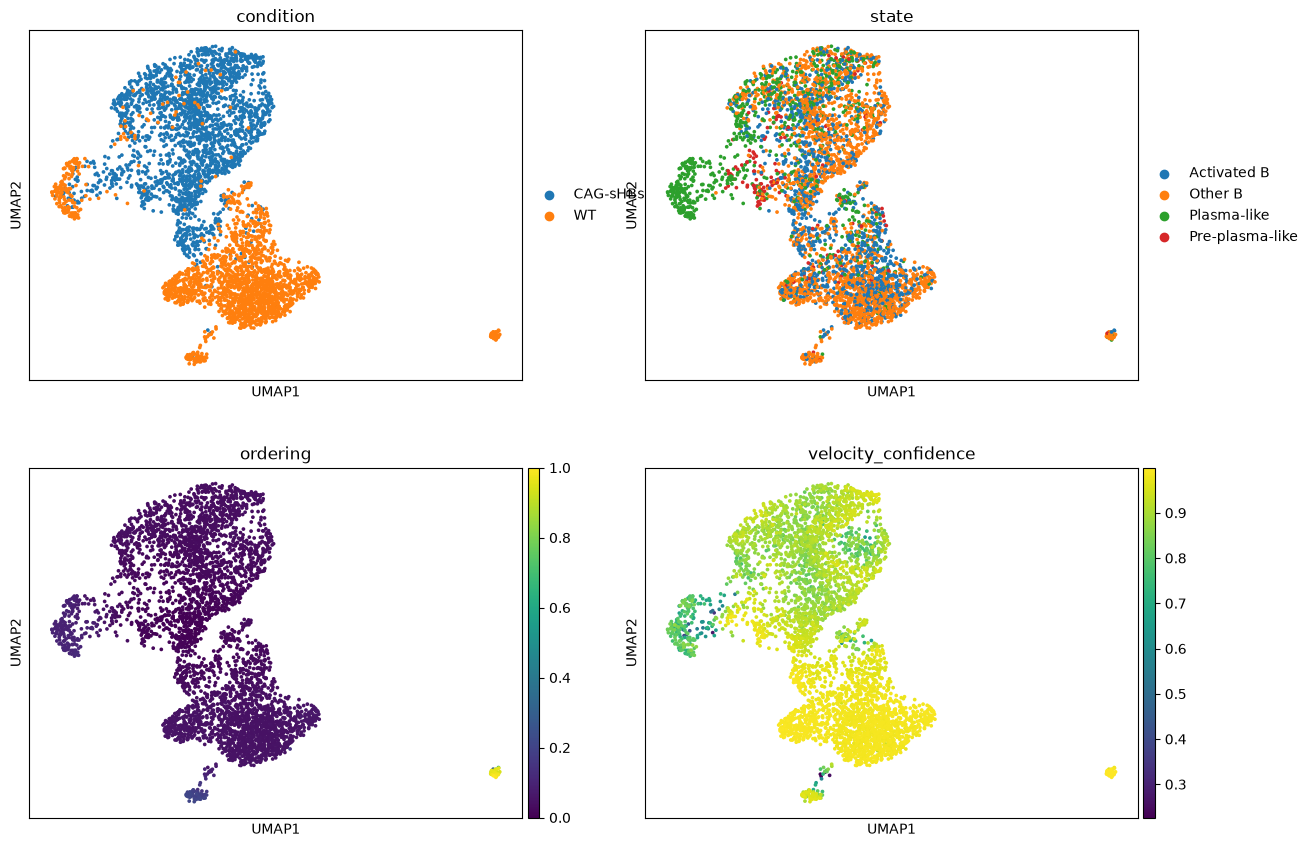

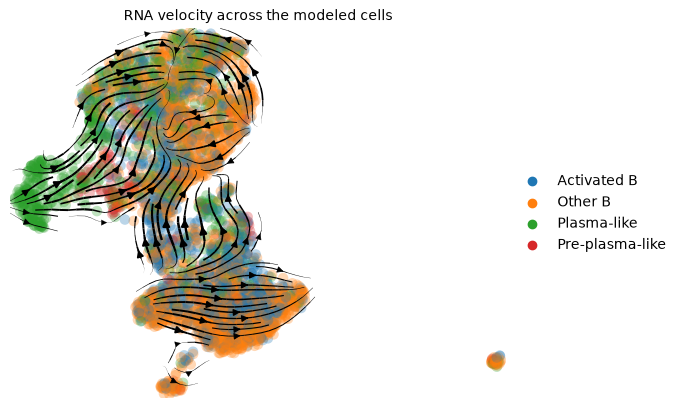

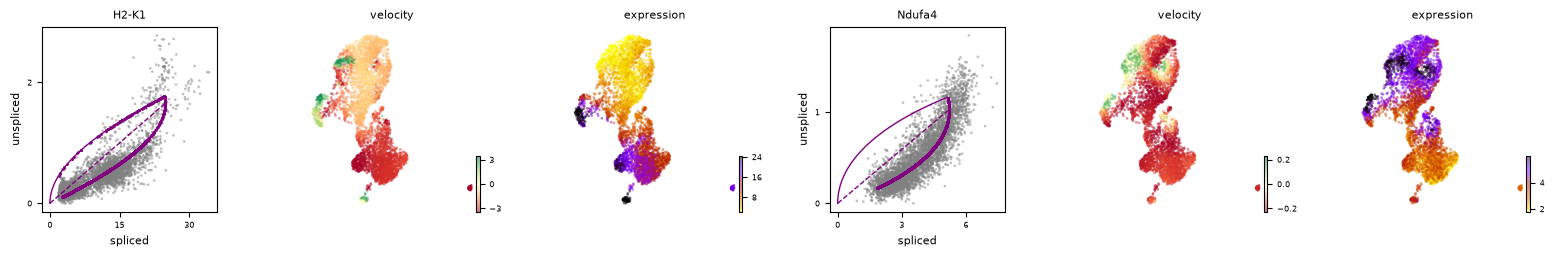

In [5]:
sc.pl.umap(
    adata, color=["condition", "state", "ordering", "velocity_confidence"], ncols=2, show=False
)
plt.show()
scv.pl.velocity_embedding_stream(adata, basis="umap", color="state", legend_loc="right margin",
                                 title="RNA velocity across the modeled cells", show=False)
plt.show()
genes = (
    adata.var.loc[adata.var.velocity_genes]
    .sort_values("fit_likelihood", ascending=False)
    .head(2)
    .index.tolist()
)
if genes:
    scv.pl.velocity(adata, var_names=genes, ncols=2, show=False)
    plt.show()

## Compare roots on the shared graph

PairScorer uses the annotated root and branches to define the scored population and anchors. The first-hit calculation can traverse other cells on the full RNA-velocity graph. The primary fit pools transitions across groups. For each endpoint, it takes the upper decile of the shared ordering, with a minimum of three anchors where available. An effective horizon of 64 discounts longer paths. **DFR** measures discounted reach to either endpoint. **CFA** describes the relative destination among roots with defined affinity. Their per-cell product gives each endpoint’s contribution. The tables retain the total and defined root counts. UFP is the remaining unresolved probability.

In [6]:
def fit_pair(scope, quantile):
    scorer = scCS.PairScorer(adata, root=ROOT, branches=FATES, obs_key="state",
                             condition_obs_key="condition", condition_order=CONDITIONS,
                             replicate_obs_key="library" if CASE == "bcell" else None)
    scorer.build_embedding(ordering_metric="ordering", cache_subset=False, verbose=False)
    scorer.fit(transition_matrix=transition, transition_scope=scope, scoring_mode="future_fate",
               future_fate_options={"effective_horizon": 64, "anchor_quantile": quantile,
                                    "min_anchor_cells": 3}, verbose=False)
    results = scorer.score_all_conditions(population="root", min_cells=1, min_replicates=1,
                                          write_to_adata=False, verbose=False)
    return scorer, results


def root_table(results):
    frames = []
    for condition, r in results.items():
        assert list(r.fate_names) == FATES
        t = adata.obs.loc[r.cell_ids, ["library", "state"]].copy()
        assert t.state.eq(ROOT).all()
        t["condition"] = condition
        t["defined"] = r.affinity_defined
        t["DFR"] = r.commitment_strength
        t["UFP"] = r.unresolved_probability
        t["coverage"] = r.transition_coverage
        for j, fate in enumerate(FATES):
            t["CFA " + fate] = r.directional_affinity[:, j]
            t["contribution " + fate] = r.commitment_contribution[:, j]
        finite = r.affinity_defined
        assert np.isnan(r.directional_affinity[~finite]).all()
        np.testing.assert_allclose(r.directional_affinity[finite].sum(axis=1), 1)
        np.testing.assert_allclose(r.commitment_contribution.sum(axis=1), t.DFR, atol=1e-9)
        np.testing.assert_allclose(t.DFR + t.UFP, 1, atol=1e-9)
        frames.append(t)
    return pd.concat(frames)


def summarize(frame, keys):
    grouped = frame.groupby(keys, observed=True)
    out = grouped[["defined","DFR","UFP","coverage"] + ["CFA " + f for f in FATES]
                  + ["contribution " + f for f in FATES]].mean()
    out.insert(0, "defined_roots", grouped.defined.sum())
    out.insert(0, "roots", grouped.size())
    return out


pair, results = fit_pair("pooled", .90)
cells = root_table(results)
assert set(cells.index) == set(adata.obs_names[adata.obs.state.eq(ROOT)])
by_condition = summarize(cells, ["condition"]).reindex(CONDITIONS)
by_library = summarize(cells, ["condition", "library"])
display(by_condition.round(4))
display(by_library.round(4))
cells.to_csv(OUTPUT / "root_cells.csv")
by_library.to_csv(OUTPUT / "root_scores_by_library.csv")
by_condition.to_csv(OUTPUT / "root_scores_by_condition.csv")

,roots,defined_roots,defined,DFR,UFP,coverage,CFA Plasma-like,CFA Pre-plasma-like,contribution Plasma-like,contribution Pre-plasma-like
condition,,,,,,,,,,
WT,600,591,0.9850,0.0359,0.9641,0.5611,0.0079,0.9921,0.0017,0.0342
CAG-sHBs,600,157,0.2617,0.0012,0.9988,0.5982,0.0039,0.9961,0.0002,0.0010


roots  ...  contribution Pre-plasma-like
condition library            ...                              
CAG-sHBs  GSM7245820    150  ...                        0.0009
          GSM7245821    150  ...                        0.0009
          GSM7245822    150  ...                        0.0015
          GSM7245823    150  ...                        0.0007
WT        GSM7245824    150  ...                        0.0320
          GSM7245825    150  ...                        0.0326
          GSM7245826    150  ...                        0.0367
          GSM7245827    150  ...                        0.0356

[8 rows x 10 columns]

## How much did the scores change?

The contrast is **CAG-sHBs minus WT**. DFR measures discounted access to either destination. Each endpoint contribution averages over all roots, including roots with zero reach. CFA averages over defined roots. Read its denominator alongside the change. Each arm mean gives equal weight to the four library means. If a library has no defined roots, its arm-level CFA stays undefined.

,roots,defined roots
condition,,
WT,600,591
CAG-sHBs,600,157


condition,WT,CAG-sHBs,change
DFR,0.0359,0.0012,-0.0346
UFP,0.9641,0.9988,0.0346
defined fraction,0.9850,0.2617,-0.7233
contribution Plasma-like,0.0017,0.0002,-0.0014
contribution Pre-plasma-like,0.0342,0.0010,-0.0332
CFA Plasma-like,0.0078,0.0031,-0.0047
CFA Pre-plasma-like,0.9922,0.9969,0.0047


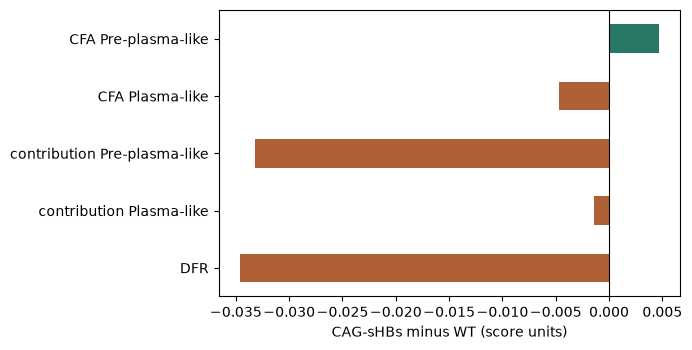

In [11]:
comp = cells.copy()
arms = ['WT', 'CAG-sHBs']
affinities = ['CFA Plasma-like', 'CFA Pre-plasma-like']
contributions = ['contribution Plasma-like', 'contribution Pre-plasma-like']
comp["defined fraction"] = comp[affinities].notna().all(axis=1)
metrics = ["DFR", "UFP", "defined fraction"] + contributions + affinities
unit = comp.groupby(["condition","library"], observed=True)[metrics].mean()
arm = unit.groupby(level="condition").agg(lambda x: x.mean(skipna=False)).reindex(arms)
effect = arm.T.copy()
effect["change"] = effect[arms[1]] - effect[arms[0]]
counts = (
    comp.groupby("condition", observed=True)["defined fraction"].agg(["size", "sum"]).reindex(arms)
)
display(counts.rename(columns={"size":"roots","sum":"defined roots"}))
display(effect.round(4))
np.testing.assert_allclose(effect.loc[contributions,"change"].sum(),effect.loc["DFR","change"],atol=1e-9)
effect.to_csv(OUTPUT / "condition_contrast.csv")
panel = effect.loc[["DFR"] + contributions + affinities,"change"]
ax = panel.plot.barh(figsize=(7,3.6),color=np.where(panel>=0,"#287867","#af6035"))
ax.axvline(0,color="black",lw=.8)
ax.set_xlabel(arms[1] + " minus " + arms[0] + " (score units)")
plt.tight_layout()
plt.show()

Mean DFR changed by **-0.0346**. Affinity is defined for 591 of 600 WT roots and 157 of 600 persistent-antigen roots. With upper-half anchors, the pooled DFR contrast changes from −0.035 to +0.071. The sign therefore depends on which observed cells count as destinations.

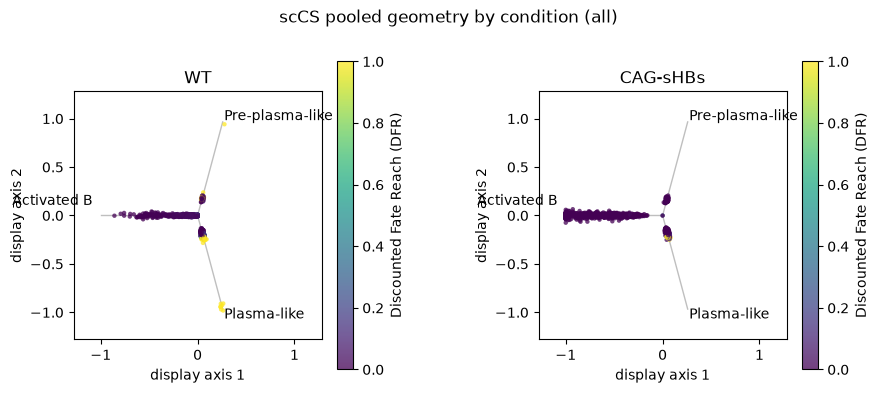

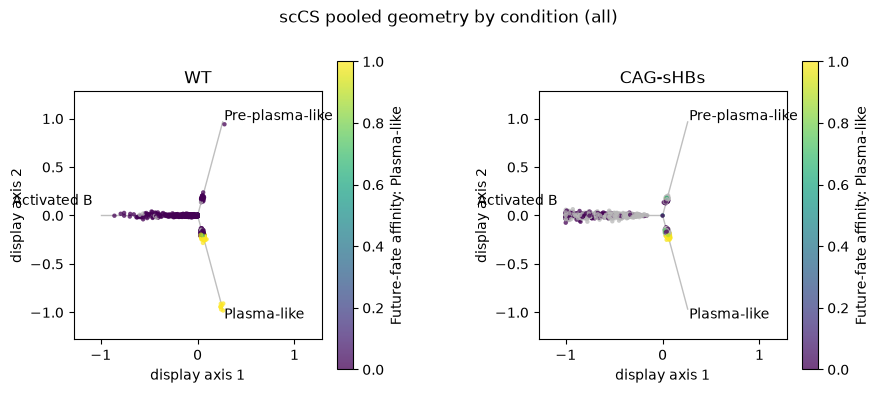

In [7]:
for metric in ["future_fate_reach", "future_fate_affinity:" + FATES[0]]:
    pair.plot_star_grid(
        results, color_by=metric, population="all", ncols=2, figsize_per_panel=(5, 4)
    )
    plt.show()

## Test dependence on anchors and graph scope

Count actual endpoint anchors by group. Then broaden the anchor set to the upper half of each endpoint label and remove between-condition transitions in a second fit. The neighborhood, kinetic parameters and ordering stay pooled. Blocking can isolate roots or leave a group without a given anchor; a zero under those circumstances is a property of the design. A third fit restricts edges to the same GEO library. Use library summaries descriptively because individual mouse-to-library assignments have not been established here.

In [8]:
checks, anchors = [], []
scopes = ["pooled", "condition"] + (["replicate"] if CASE == "bcell" else [])
for scope in scopes:
    for quantile in [.5, .9]:
        scorer, res = (
            (pair, results) if (scope, quantile) == ("pooled", 0.9) else fit_pair(scope, quantile)
        )
        summ = summarize(root_table(res), ["condition"])
        checks.append(summ.assign(scope=scope, anchor_quantile=quantile).reset_index())
        if scope == "pooled":
            scorer.result.write_to_adata(adata)
            anchor_ids = adata.uns["sccs_v08"]["future_fate"]["anchor_cell_ids"]
            for fate, ids in anchor_ids.items():
                for cond in CONDITIONS:
                    names = adata.obs_names[adata.obs.condition.eq(cond)]
                    anchors.append((quantile, fate, cond, len(names.intersection(ids))))
anchor_counts = pd.DataFrame(anchors, columns=["quantile", "endpoint", "condition", "anchors"])
diagnostics = pd.concat(checks, ignore_index=True)
display(anchor_counts.pivot(index=["quantile","endpoint"], columns="condition", values="anchors"))
display(diagnostics[["scope", "anchor_quantile", "condition", "roots", "defined_roots", "DFR",
                     "CFA " + FATES[0], "contribution " + FATES[0]]].round(4))
anchor_counts.to_csv(OUTPUT / "anchor_counts.csv", index=False)
diagnostics.to_csv(OUTPUT / "graph_sensitivity.csv", index=False)

condition                 CAG-sHBs   WT
quantile endpoint                      
0.5      Plasma-like           170  230
         Pre-plasma-like        40   40
0.9      Plasma-like            12   68
         Pre-plasma-like         0   16

,scope,anchor_quantile,condition,roots,defined_roots,DFR,CFA Plasma-like,contribution Plasma-like
0,pooled,0.5,CAG-sHBs,600,600,0.3828,0.9361,0.3597
1,pooled,0.5,WT,600,600,0.3119,0.7699,0.2408
2,pooled,0.9,CAG-sHBs,600,157,0.0012,0.0039,0.0002
3,pooled,0.9,WT,600,591,0.0359,0.0079,0.0017
4,condition,0.5,CAG-sHBs,600,600,0.3748,0.9400,0.3534
5,condition,0.5,WT,600,600,0.3185,0.7675,0.2460
6,condition,0.9,CAG-sHBs,600,0,0.0000,NaN,0.0000
7,condition,0.9,WT,600,597,0.0381,0.0076,0.0018
8,replicate,0.5,CAG-sHBs,600,600,0.2113,0.9371,0.2000
9,replicate,0.5,WT,600,596,0.1752,0.6985,0.1227


In [9]:
pair.result.write_to_adata(adata)
adata.obsp["T_velocity"] = transition
adata.write_h5ad(OUTPUT / "fitted.h5ad", compression="gzip")
adata.var.filter(regex=r"^fit_|^velocity_genes$").to_csv(OUTPUT / "gene_fits.csv")
(OUTPUT / "versions.json").write_text(
    json.dumps({"python": platform.python_version(), "packages": versions, "seed": SEED}, indent=2)
)
print(f"Saved model and audit tables in tutorial_outputs/{CASE}/")

Saved model and audit tables in tutorial_outputs/bcell/


### Narrow the plasma-like endpoint

Keep the primary fit on disk and score the same roots on the same transition graph. Require *Prdm1* and either *Jchain* or *Sdc1* within the broad plasma-like set. A shift in absolute reach measures how much the result depends on exactly which cells serve as destinations.

,roots,defined_roots,strict_plasma_candidates,DFR,CFA Plasma-like,contribution Plasma-like
condition,,,,,,
WT,600,591,112,0.0359,0.0069,0.0016
CAG-sHBs,600,157,101,0.0012,0.0037,0.0002


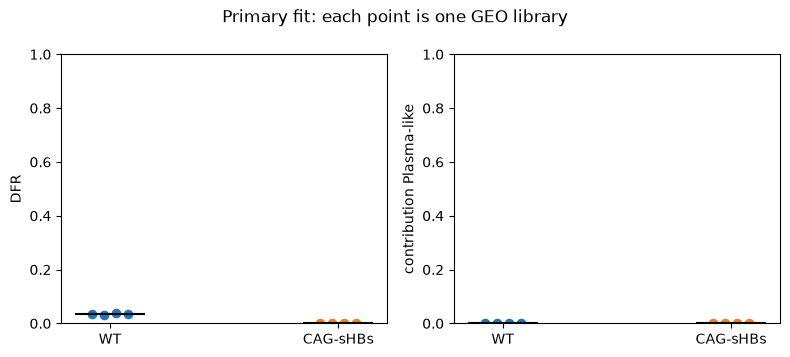

In [10]:
# Reopen the primary fit and change only the RNA endpoint label.
import anndata as ad
strict_adata = ad.read_h5ad(OUTPUT / "fitted.h5ad")
strict_adata.obs["strict_state"] = strict_adata.obs.state.astype(str)
broad_only = strict_adata.obs.state.eq("Plasma-like") & ~strict_adata.obs.strict_plasma.eq(True)
strict_adata.obs.loc[broad_only, "strict_state"] = "Other B"
strict_pair = scCS.PairScorer(strict_adata, root=ROOT, branches=FATES, obs_key="strict_state",
                              condition_obs_key="condition", condition_order=CONDITIONS,
                              replicate_obs_key="library")
strict_pair.build_embedding(ordering_metric="ordering", cache_subset=False, verbose=False)
strict_pair.fit(transition_matrix=strict_adata.obsp["T_velocity"], transition_scope="pooled",
                scoring_mode="future_fate", future_fate_options={"effective_horizon": 64,
                "anchor_quantile": .9, "min_anchor_cells": 3}, verbose=False)
strict_results = strict_pair.score_all_conditions(population="root", min_cells=1, min_replicates=1,
                                                   write_to_adata=False, verbose=False)
strict_rows = []
for condition, r in strict_results.items():
    defined = r.affinity_defined
    strict_rows.append(
        {
            "condition": condition,
            "roots": len(r.cell_ids),
            "defined_roots": defined.sum(),
            "strict_plasma_candidates": int(
                (
                    strict_adata.obs.strict_plasma.eq(True)
                    & strict_adata.obs.condition.eq(condition)
                ).sum()
            ),
            "DFR": r.commitment_strength.mean(),
            "CFA Plasma-like": r.directional_affinity[defined, 0].mean()
            if defined.any()
            else np.nan,
            "contribution Plasma-like": r.commitment_contribution[:, 0].mean(),
        }
    )
strict_check = pd.DataFrame(strict_rows).set_index("condition")
display(strict_check.round(4))
strict_check.to_csv(OUTPUT / "strict_endpoint_scores.csv")

per_library = pd.read_csv(OUTPUT / "root_scores_by_library.csv")
fig, axes = plt.subplots(1, 2, figsize=(8, 3.6), sharey=False)
for ax, metric in zip(axes, ["DFR", "contribution Plasma-like"]):
    for x, condition in enumerate(CONDITIONS):
        values = per_library.loc[per_library.condition.eq(condition), metric].to_numpy()
        ax.scatter(x + np.linspace(-.08, .08, len(values)), values, s=35)
        ax.plot([x-.15,x+.15], [values.mean()]*2, color="black")
    ax.set(xticks=range(2), xticklabels=CONDITIONS, ylabel=metric, ylim=(0, 1))
fig.suptitle("Primary fit: each point is one GEO library")
fig.tight_layout()
plt.show()

## Interpretation

With upper-decile anchors, mean discounted reach is 0.0359 in WT and 0.00125 in CAG-sHBs. Affinity is defined for 591/600 WT and 157/600 CAG-sHBs activated roots. All 16 pre-plasma-like anchors are WT. Restricting transitions to their own condition leaves zero CAG-sHBs roots with defined affinity. The narrower plasma-like RNA definition gives similar reach in the pooled graph.

Broadening the anchor set to the upper half makes affinity defined for all 1,200 roots and reverses the reach contrast: WT 0.312 and CAG-sHBs 0.383. Before graph subsampling, 319/28,366 WT eligible cells (1.12%) and 4,282/36,028 CAG-sHBs eligible cells (11.89%) meet the broad plasma-like rule. The held-out germinal-center marker *Aicda* is detected in 81.2% of CAG-sHBs activated roots versus 1.4% of WT activated roots before sampling. The same gate captures different transcriptional compositions, and the broad plasma-like frequency measures an RNA signature in sorted cells.

These data provide a worked example of how PairScorer can expose dependence on endpoint selection, graph scope and root comparability. The authors measured defective antibody-secreting cell formation experimentally. This RNA-only reanalysis does not independently establish or quantify that functional deficit. The eight per-library summaries are descriptive.